# Import

In [1]:
import warnings
warnings.filterwarnings("ignore")

import xdas as xd
import xarray as xr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.offsetbox import AnchoredText
from matplotlib.patches import Rectangle

from utils.utils_ml import (
    preprocess_disp,
    prepare_windows,
    phases_perc,
    phases_snr,
    get_hypodist,
    estimate_ml_ISNET,
    preprocess_strainrate,
    get_epicentral_distance,
    nansmad
)

In [2]:
#Plot params
# -- Axes --
plt.rcParams['axes.spines.bottom'] = True
plt.rcParams['axes.spines.left'] = True
plt.rcParams['axes.spines.right'] = True
plt.rcParams['axes.spines.top'] = True
plt.rcParams['grid.linewidth'] = 0.5
plt.rcParams['axes.axisbelow'] = False
plt.rcParams['axes.linewidth'] = 0.5
plt.rcParams['axes.ymargin'] = 0.1
plt.rcParams["font.size"] = 10
plt.rcParams["figure.dpi"] = 600
# -- Grid --
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['grid.color'] = 'grey'
plt.rcParams['grid.linestyle'] = "-"
# -- Ticks and tick labels --
plt.rcParams['axes.edgecolor'] = 'k'
plt.rcParams['xtick.color'] = 'k'
plt.rcParams['ytick.color'] = 'k'
plt.rcParams['xtick.major.width'] = 0.5
plt.rcParams['ytick.major.width'] = 1.0
plt.rcParams['xtick.major.size'] = 1.5
plt.rcParams['ytick.major.size'] = 2.5
# -- Fonts --
plt.rcParams['font.size'] = 8
plt.rcParams['text.color'] = 'k'
plt.rcParams['axes.labelcolor'] = 'k'
plt.rcParams['axes.labelsize'] = 8
# -- Saving Options --
plt.rcParams['savefig.bbox'] = 'tight'
plt.rcParams['savefig.dpi'] = 600
plt.rcParams['savefig.transparent'] = False
# -- Plot Styles --
plt.rcParams['lines.linewidth'] = 1
plt.rcParams["lines.markersize"] = 0.1
plt.rcParams["lines.markeredgewidth"] = 0.1
plt.rcParams["figure.dpi"] = 300

mm = 1/25.4

# Info and Parameters

In [3]:
# Event info
event_id = "17933b"
#catalog = pd.read_csv("./input/10/data/ISNET_catalog.csv")
#event_info = catalog[catalog["#eventid"] == event_id].iloc[0]

# Input files
tito_ch1_coords = pd.read_csv("./utils/tito_ch1_geometry_gl_40.csv")
tito_ch2_coords = pd.read_csv("./utils/tito_ch2_geometry_gl_40.csv")

# Parameters
pre_win = 0.2
wlen = 5.0
avg_len = 6000
noise_wlen = 5.0
smad_thre = 4
tapering_frac = 0.05
snr_threshold = {  # Signal to Noise Ratio threshold
    "P": 3.0,
    "S": 3.0,
}
max_perc_lvl = 100  # Percentile to be used as max estimation
lowcut, highcut = 1.0, 25.0  # High and low cut frequencies in Hz


# Reference location from ISNet catalog

In [19]:
event_info = {'time': '2025-12-25 14:54:52', 'latitude': 40.655, 'longitude': 15.632, 'depth': 6.1, 'ml': 0.7}

# Load picks

In [20]:
picks = pd.read_csv("./results/gamma_PN_DAS_local_picks/event.txt")
picks_df = picks.rename(columns={"OFFSET": "offset", "PHASE": "phase"})
# Load picks
picks_df["phase"] = picks_df["phase"].str.upper()
picks_df["time"] = pd.to_datetime(
    picks_df["TIME"],
    format="mixed",
    utc=True,
    errors="coerce",
)

# Processing

In [21]:

dist_sel = (60.0, None) # Select useful distance range for CH2
da = xd.open_mfdataarray("./traces_DAS/SR_DS_CH2_2025-12-25_14-54-52_UTC.nc").sel(distance=slice(*dist_sel))

# Selection in time
start = np.datetime64(picks_df["time"].min()) - np.timedelta64(40, "s")
end = np.datetime64(picks_df["time"].max()) + np.timedelta64(40, "s")
da = da.sel(time=slice(start, end))
# Prepare dictionaries to store results
max_dict = {}
snr_dict = {}
mag_dict = {}
hyp_dict = {}

# Load coordinates for the corresponding cable
tito_cable_coords = tito_ch2_coords
# Open the single DataArray and select the distance range

if da["distance"].values[-1] >= tito_cable_coords["distance"].values[-1]:
    da = da.sel(distance=slice(None, tito_cable_coords["distance"].values[-1]))
# Attach coords headers to the DataArray
mindist = min(tito_cable_coords["distance"].min(), da["distance"].values.min())
maxdist = max(tito_cable_coords["distance"].max(), da["distance"].values.max())
da = da.sel(distance=slice(mindist, maxdist))
tito_cable_coords = tito_cable_coords.set_index("distance").reindex(da["distance"].values, method="nearest").reset_index()
# Append cable coords as headers
da = da.assign_coords(latitude=("distance", tito_cable_coords["latitude"].values))
da = da.assign_coords(longitude=("distance", tito_cable_coords["longitude"].values))
da = da.assign_coords(elevation=("distance", tito_cable_coords["elevation_m"].values))

# Select P and S wave windows and preprocess the data
starttime, endtime, toa = prepare_windows(
    picks_df, da, pre_win=pre_win, wlen=wlen, noise_wlen=noise_wlen, smad_thre=smad_thre
)
data = preprocess_disp(da, tapering_frac, lowcut, highcut, avg_len)
# Evaluate the maximum amplitude and SNR for each phase
max_ampl, max_mask = phases_perc(data, starttime, endtime, max_perc_lvl)
snr, max_ampl, max_mask = phases_snr(max_ampl, snr_threshold, max_mask, phases=["P", "S"])
# Evaluate hypocentral distance
hyp = get_hypodist(event_info, da)
tol = xd.get_sampling_interval(da, dim="distance")
start = da["distance"].values[0]
end = da["distance"].values[-1]
start_nearest = float(hyp.distance.sel(distance=start, method="nearest", tolerance=tol).values)
end_nearest = float(hyp.distance.sel(distance=end, method="nearest", tolerance=tol).values)
hyp = xd.DataArray.from_xarray(hyp.sel(distance=slice(start_nearest, end_nearest)))
# Get epicentral distance if needed
epi = get_epicentral_distance(event_info, tito_cable_coords).sel(distance=slice(start_nearest, end_nearest))
# Estimate local magnitude using ISNET attenuation relation (Bobbio et al., 2009)
local_mag = estimate_ml_ISNET(max_ampl, hyp)
# Store results
hyp_dict = hyp
max_dict = max_ampl
snr_dict = snr
mag_dict = local_mag


# Picked data and magnitude estimates

In [22]:
t0 = np.datetime64(event_info["time"])
da = preprocess_strainrate(da, tapering_frac=0.05, lowcut=lowcut, highcut=highcut)

# Select SNR thresholds and evaluate median values along the two cables
mask_ch = snr_dict["S"] >= 2.0

n_nan = np.sum(np.isnan(mag_dict.values))
n_est = len(mag_dict.values) - n_nan

catalog_mag = event_info["ml"]
ev_lat, ev_lon = event_info["latitude"], event_info["longitude"]
das_mag, das_mag_err = np.nanmedian(mag_dict.values[mask_ch]), nansmad(mag_dict.values[mask_ch])

In [23]:
t0 = np.datetime64(event_info["time"])
da = preprocess_strainrate(da, tapering_frac=0.05, lowcut=lowcut, highcut=highcut)

# Select SNR thresholds and evaluate median values along the two cables
mask_ch = snr_dict["S"] >= 2.0

n_nan = np.sum(np.isnan(mag_dict.values))
n_est = len(mag_dict.values) - n_nan

catalog_mag = event_info["ml"]
ev_lat, ev_lon = event_info["latitude"], event_info["longitude"]
das_mag, das_mag_err = np.nanmedian(mag_dict.values[mask_ch]), nansmad(mag_dict.values[mask_ch])


# Prepare picks and windows for each cable
starttime_, endtime, toa = prepare_windows(
    picks_df, da, pre_win=pre_win, wlen=wlen, noise_wlen=noise_wlen, smad_thre=smad_thre
)

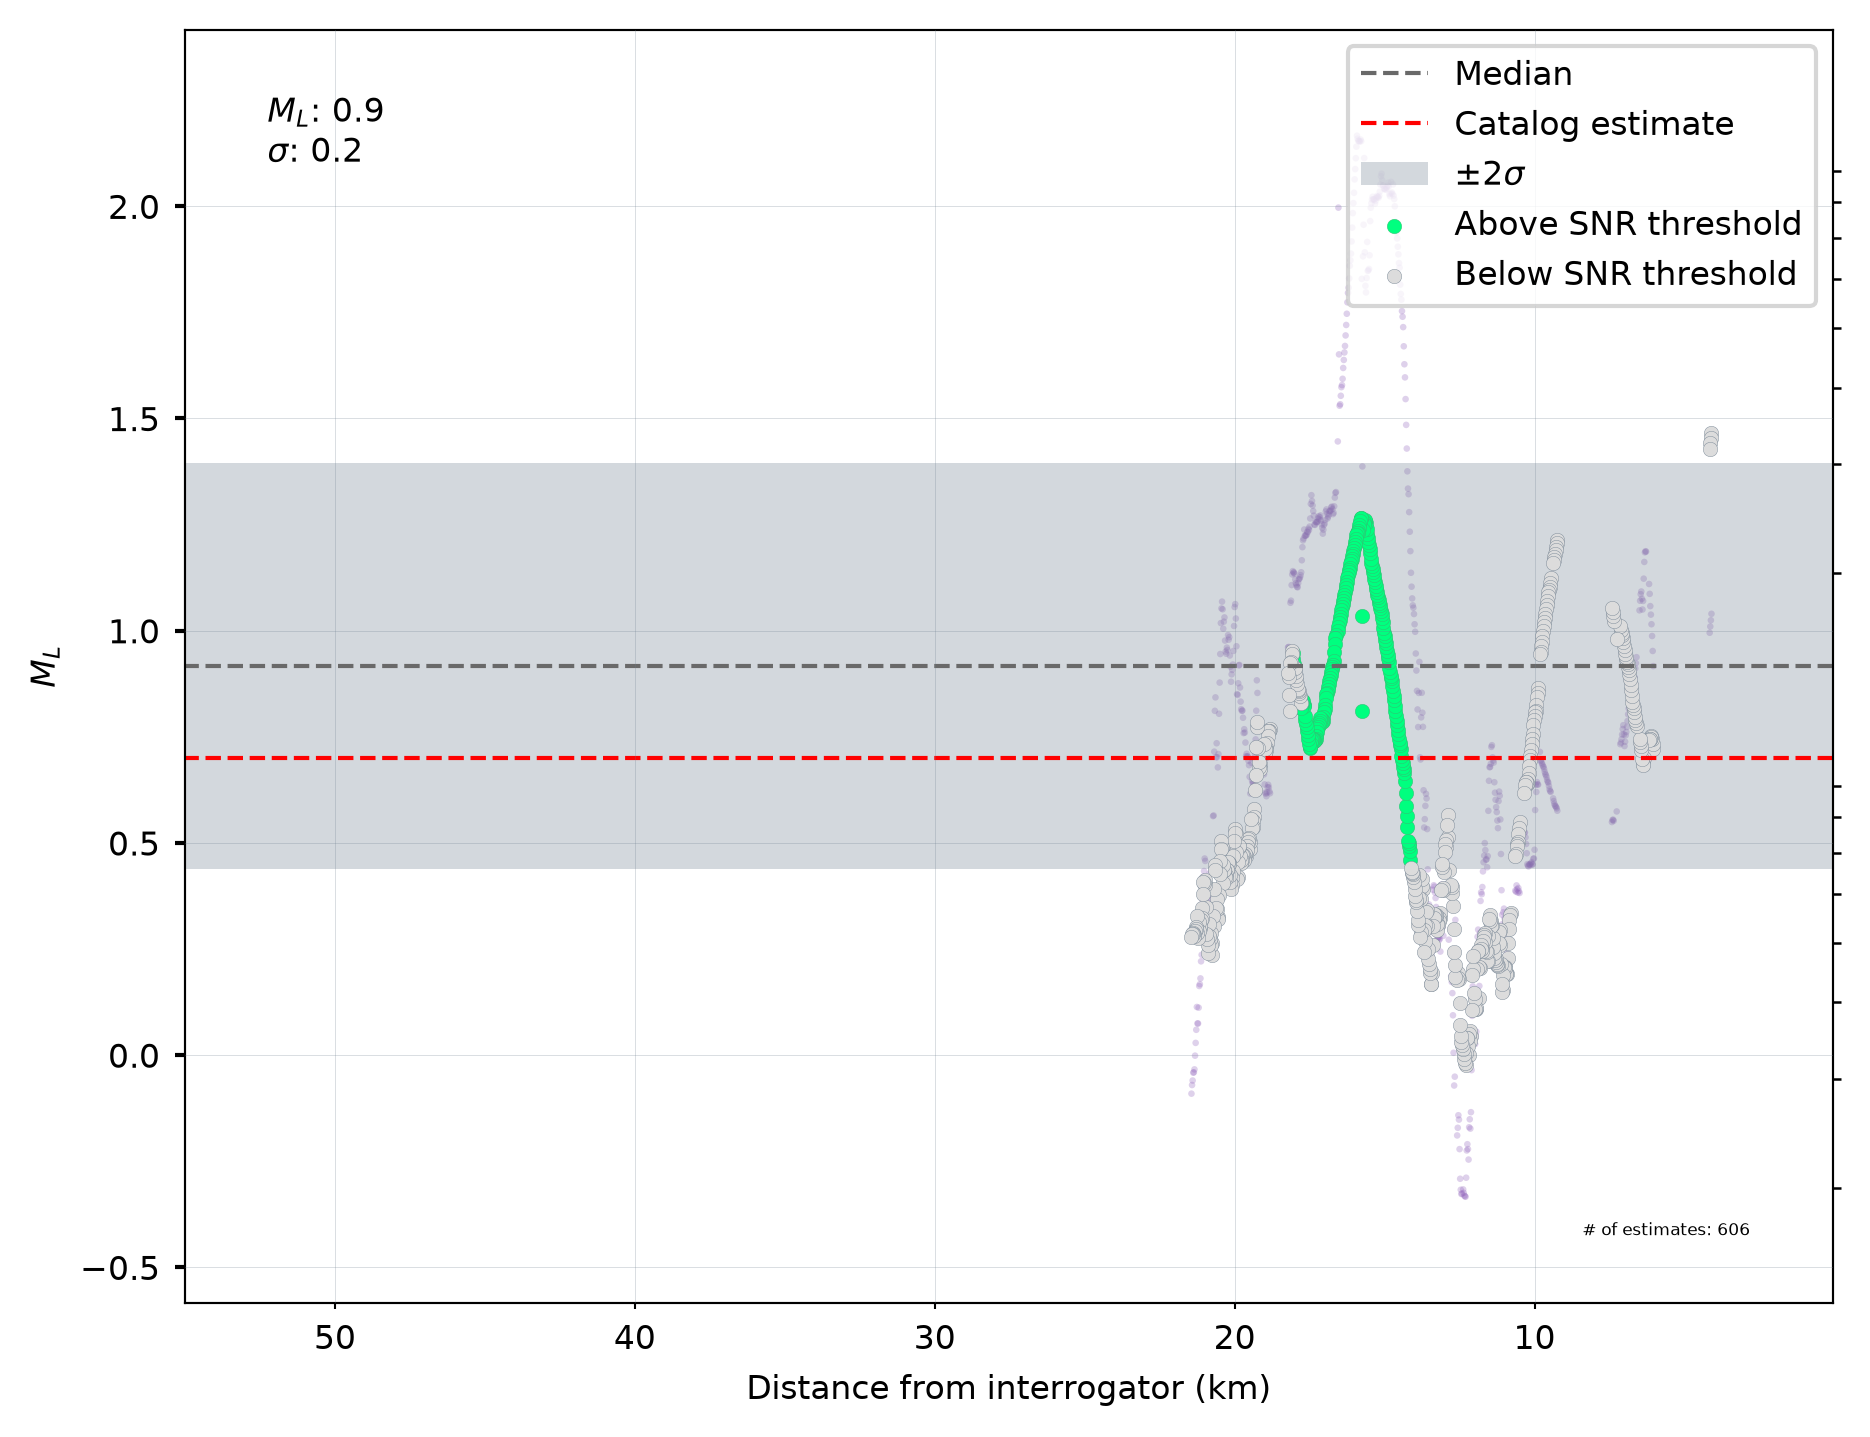

In [25]:
length = np.nanmax(da["distance"].values) - np.nanmin(da["distance"].values)
fig, axes = plt.subplots(
    nrows=1, 
    ncols=1,
    figsize=(180*mm, 140*mm),
    dpi=300
)
plt.subplots_adjust(hspace=0.0, wspace=0.0)
vlim = np.percentile(np.abs(da.values), 98)
ymin = t0 - np.timedelta64(7, "s")
ymax = t0 + np.timedelta64(30, "s")
for ix, da in enumerate([da]):
    ax = axes
    mag = mag_dict
    das_mag, das_mag_err = (das_mag, das_mag_err)
    avg_dasmag = np.nanmedian(mag_dict.values[mask_ch])
    mask = mask_ch
    n_est = n_est
    snr = snr_dict 

    ax.grid(True, color='slategray', linestyle='-', linewidth=0.2, zorder=0)
    distances = mag["distance"].values * 1e-3  # Convert to km
    ax.hlines(das_mag, np.min(distances), np.max(distances), color="dimgrey", linestyle="--", label="Median")
    ax.hlines(catalog_mag, np.min(distances), np.max(distances), color="r", linestyle="--", label="Catalog estimate")
    ax.fill_between(
        [np.min(distances), np.max(distances)],
        das_mag - 2 * das_mag_err,
        das_mag + 2 * das_mag_err,
        facecolor="slategray",
        edgecolor=None,
        alpha=0.3,
        label="$\pm 2\sigma$",
    )
    ax.scatter(distances[mask], mag[mask], s=12, marker="o", facecolor="springgreen", edgecolors="mediumseagreen", linewidths=0.1, label="Above SNR threshold")
    ax.scatter(distances[~mask], mag[~mask], s=12, marker="o", facecolor="gainsboro", edgecolors="slategray", linewidths=0.1, label="Below SNR threshold")
    ax.set_xlabel("Distance from interrogator (km)")
    ax.tick_params(axis='x', which='both', bottom=True, top=False, labelbottom=True)
    if ix == 0:
        xmin = np.max(distances)
        xmax = np.min(distances)
    else:   
        xmin = np.min(distances)
        xmax = np.max(distances)
    if ix == 0:
        ax.set_ylabel("$M_L$")
        ax.tick_params(axis='y', labelcolor="k")
    else:
        ax.set_ylabel("")
        ax.set_yticks([])
    ax.set_xlim([xmin, xmax])
    ax.set_ylim([avg_dasmag - 1.5, avg_dasmag + 1.5])
    ax.text(0.05, 0.95, f"$M_L$: {das_mag:.1f}\n$\sigma$: {das_mag_err:.1f}", transform=ax.transAxes, ha="left", va="top")
    if ix==1:
        ax.text(0.2, 0.95, f"$M_L$ $ISNet$: {catalog_mag:.1f}", transform=ax.transAxes, ha="left", va="top", color="r")
        ax.legend(fontsize=4, loc="upper right", ncols=2, handlelength=1.5, handletextpad=0.5, borderpad=0.5, borderaxespad=0.5, frameon=False)
    ax.text(0.95, 0.05, f"# of estimates: {n_est}", transform=ax.transAxes, ha="right", va="bottom", fontsize=4)
    ax.patch.set_visible(False)         # Make SNR axis background transparent
    ax_snr = ax.twinx()
    ax_snr.set_zorder(ax.get_zorder() - 1)  # Move SNR axis behind main axis
    ax_snr.scatter(distances, snr["S"].values, color="tab:purple", s=2.5, marker="o", edgecolors="none", alpha=0.3, zorder=1)
    ax_snr.set_yscale("log")
    if ix == 0:
        ax_snr.set_ylabel("")
        ax_snr.set_yticks([])
    else:
        ax_snr.set_ylabel("$SNR^{S}$", color="tab:purple")
        ax_snr.tick_params(axis='y', labelcolor="tab:purple")
    ax.legend()
